In [19]:
"""
Keystroke dynamics: identification baselines (CMU benchmark)
"""
import os
import sys
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
import matplotlib
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
%matplotlib inline
from scipy.stats import skew
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import PowerTransformer, StandardScaler

path = "lab_dataset.csv"
df = pd.read_csv(path)
all_users = sorted(df["subject"].unique())
rng = np.random.default_rng(SEED)

# flag for the benchmark(runs all types of the features)
BENCHMARK = False

In [20]:
print("Shape:", df.shape)
print("Users:", df["subject"].nunique())
print("Sessions:", sorted(df["sessionIndex"].unique()))
print("Missing values:", int(df.isna().sum().sum()))

feature_cols = [c for c in df.columns if c.startswith(("H.", "DD.", "UD."))]
print("Number of timing features:", len(feature_cols))

Shape: (50400, 39)
Users: 126
Sessions: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8)]
Missing values: 0
Number of timing features: 31


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50400 entries, 0 to 50399
Data columns (total 39 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   subject          50400 non-null  object 
 1   session          50400 non-null  object 
 2   sessionIndex     50400 non-null  int64  
 3   rep              50400 non-null  int64  
 4   time             50400 non-null  float64
 5   errors           50400 non-null  int64  
 6   H.period         50400 non-null  float64
 7   DD.period.t      50400 non-null  float64
 8   UD.period.t      50400 non-null  float64
 9   H.t              50400 non-null  float64
 10  DD.t.i           50400 non-null  float64
 11  UD.t.i           50400 non-null  float64
 12  H.i              50400 non-null  float64
 13  DD.i.e           50400 non-null  float64
 14  UD.i.e           50400 non-null  float64
 15  H.e              50400 non-null  float64
 16  DD.e.five        50400 non-null  float64
 17  UD.e.five   

In [22]:
df.sample(5)

,subject,session,sessionIndex,rep,time,errors,H.period,DD.period.t,UD.period.t,H.t,...,UD.a.n,H.n,DD.n.l,UD.n.l,H.l,DD.l.Return,UD.l.Return,H.Return,psr,totaltime
46364,s318,2018.05.18_15.26.12,8,15,32.2140,0,0.1045,0.1311,0.0266,0.1145,...,-0.0206,0.0739,0.1862,0.1123,0.0762,0.1713,0.0951,0.1175,365,1.5434
5310,s018,2006.10.19_11.07.04,3,11,26.2512,0,0.0826,0.1897,0.1071,0.0958,...,0.0375,0.1180,0.0235,-0.0945,0.1246,0.2712,0.1466,0.0533,111,1.9399
50270,s329,2018.08.21_14.04.55,6,21,67.2512,1,0.0863,0.2215,0.1352,0.0789,...,-0.0406,0.1003,0.0728,-0.0275,0.1251,0.2959,0.1708,0.0665,271,1.9737
44932,s315,2018.05.14_10.25.48,3,33,99.3100,0,0.1166,0.1231,0.0065,0.1184,...,0.0040,0.1272,0.1079,-0.0193,0.0923,0.3148,0.2225,0.0620,133,1.6983
2665,s010,2006.11.02_09.41.33,6,16,36.5667,1,0.0948,0.1681,0.0733,0.0581,...,0.0386,0.0792,0.2011,0.1219,0.0808,0.2287,0.1479,0.0945,266,1.6558


In [23]:
def pick(n):
    return sorted(rng.choice(all_users, size=min(n, len(all_users)), replace=False))


def finish(name):
    plt.tight_layout()
    plt.savefig(f"results/{name}.png", dpi=120)
    plt.show()

In [24]:
"""
Quick EDA for the keystroke dataset.
Run:  python eda.py path/to/your_file.csv
Saves plots to results/eda_*.png and prints the key facts.
"""

os.makedirs("results", exist_ok=True)

H = [c for c in df.columns if c.startswith("H.")]
DD = [c for c in df.columns if c.startswith("DD.")]
UD = [c for c in df.columns if c.startswith("UD.")]
feats = H + DD + UD
print(f"Rows: {len(df)}, users: {df['subject'].nunique()}, features: {len(feats)} (H={len(H)}, DD={len(DD)}, UD={len(UD)})")

# 1. Class balance
counts = df.groupby("subject").size()
print("Rows per user: min", counts.min(), "max", counts.max())

# 2. Basic sanity: missing values, ranges, negatives
print("Missing values in features:", int(df[feats].isna().sum().sum()))
print("\nFeature summary (seconds):")
print(df[feats].describe().T[["mean", "std", "min", "max"]].round(4).to_string())
print(f"\nShare of negative UD values: {(df[UD] < 0).values.mean():.3%} (negative = next key pressed before release)")

# 3. Redundancy check: DD should equal H(previous key) + UD
diffs = []
# H, DD and UD columns are in key order, so DD[i] and UD[i] belong to key H[i]
for h, d, u in zip(H[:-1], DD, UD):
    diffs.append(np.abs(df[d] - (df[h] + df[u])).max())
print("Max |DD - (H + UD)| across rows:", round(max(diffs), 6), "(near 0 means DD is redundant)")

# 4. Outliers: rows with very large values
big = (df[feats] > 5).any(axis=1).sum()
print("Rows with any timing > 5 s:", int(big))

Rows: 50400, users: 126, features: 31 (H=11, DD=10, UD=10)
Rows per user: min 400 max 400
Missing values in features: 0

Feature summary (seconds):
                   mean     std     min      max
H.period         0.0943  0.0282  0.0014   0.3761
H.t              0.0889  0.0276  0.0014   0.2941
H.i              0.0837  0.0275  0.0032   0.3374
H.e              0.0919  0.0315  0.0021   0.3440
H.five           0.0810  0.0239  0.0014   0.2590
H.Shift.r        0.0998  0.0315  0.0014   0.3508
H.o              0.0903  0.0303  0.0014   0.6872
H.a              0.1056  0.0351  0.0027   2.0353
H.n              0.0923  0.0310  0.0037   0.3748
H.l              0.0975  0.0280  0.0024   0.3407
H.Return         0.0894  0.0269  0.0016   0.2651
DD.period.t      0.2374  0.1788  0.0071  12.5061
DD.t.i           0.1582  0.1016  0.0011   4.9197
DD.i.e           0.1469  0.1646  0.0014  25.9873
DD.e.five        0.3331  0.2281  0.0013   4.9618
DD.five.Shift.r  0.3985  0.2046  0.1505   8.3702
DD.Shift.r.o     0.

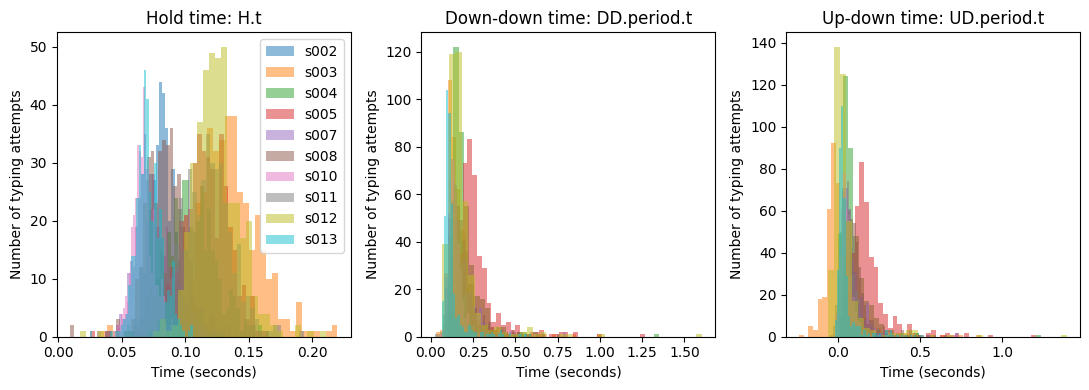

In [25]:
# 5. Hold-time histograms for 4 users
users = sorted(df["subject"].unique())[:10]
fig, axes = plt.subplots(1, 3, figsize=(11, 4))
for u in users:
    axes[0].hist(df.loc[df.subject == u, H[1]], bins=40, alpha=0.5, label=u)
    axes[1].hist(df.loc[df.subject == u, DD[0]], bins=40, alpha=0.5, label=u)
    axes[2].hist(df.loc[df.subject == u, UD[0]], bins=40, alpha=0.5, label=u)
axes[0].set_title(f"Hold time: {H[1]}"); axes[1].set_title(f"Down-down time: {DD[0]}"); axes[2].set_title(f"Up-down time: {UD[0]}")
for ax in axes:
    ax.set_xlabel("Time (seconds)")
    ax.set_ylabel("Number of typing attempts")
axes[0].legend(); plt.tight_layout(); plt.savefig("results/eda_hist.png", dpi=120); plt.show()

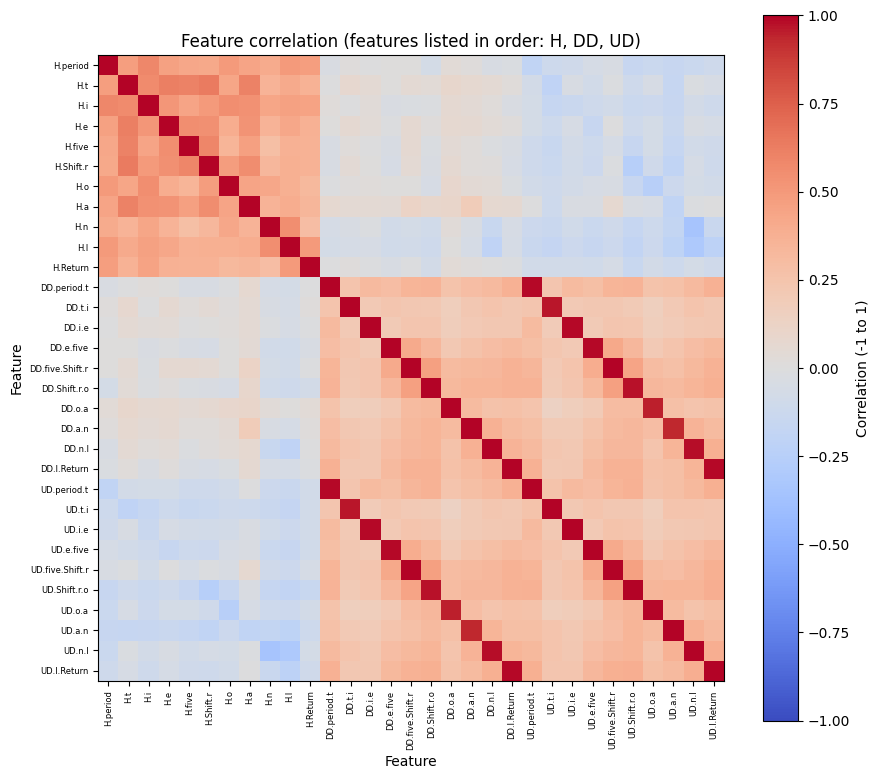

In [26]:
# 6. Correlation heatmap
plt.figure(figsize=(9, 8))
plt.imshow(df[feats].corr(), cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation (-1 to 1)")
plt.xticks(range(len(feats)), feats, rotation=90, fontsize=6)
plt.yticks(range(len(feats)), feats, fontsize=6)
plt.xlabel("Feature"); plt.ylabel("Feature")
plt.title("Feature correlation (features listed in order: H, DD, UD)")
plt.tight_layout(); plt.savefig("results/eda_corr.png", dpi=120); plt.show()

Users: ['s138', 's147', 's316', 's319']

user   mean H-H   mean H-UD   mean DD-UD (matching pairs)
s138       0.17        0.07         1.00
s147       0.25       -0.07         0.99
s316       0.03       -0.01         0.95
s319       0.14        0.04         0.98


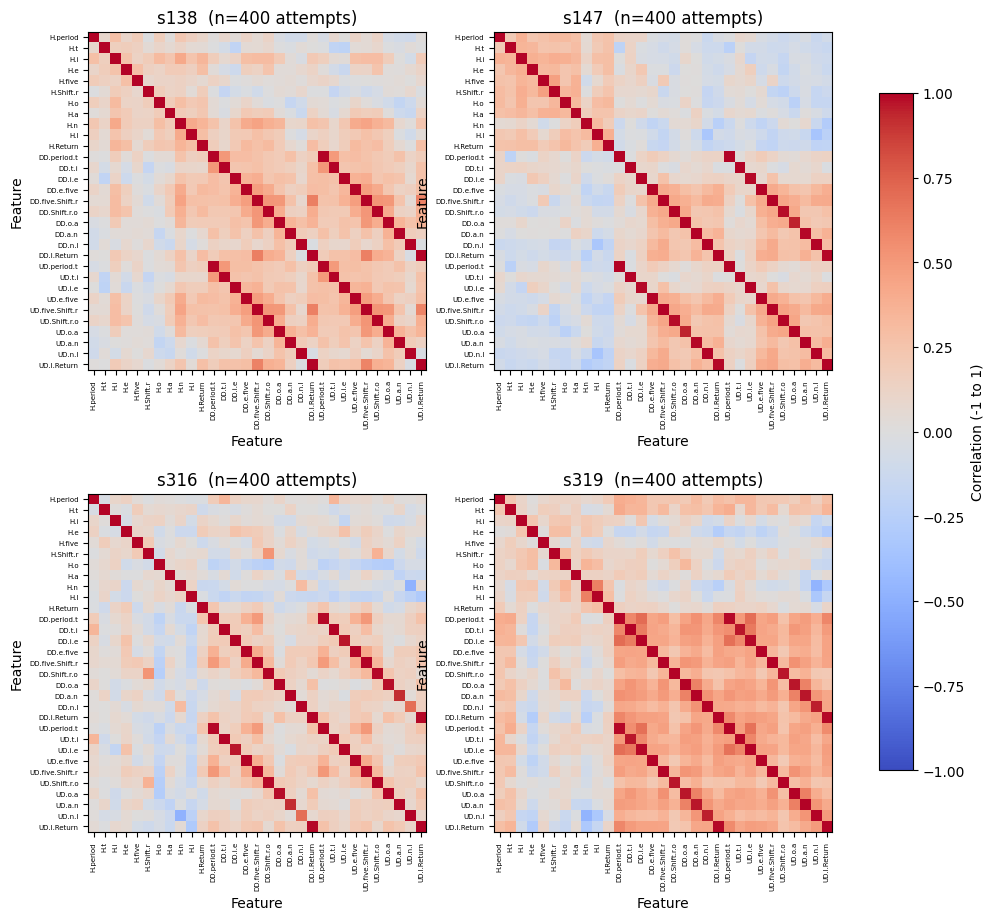

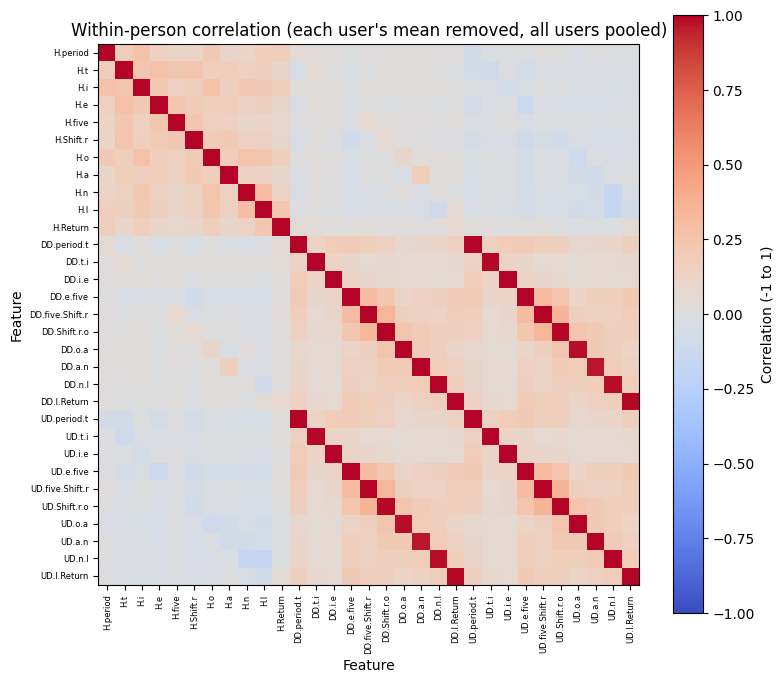


Within-person, all users: H-H 0.17, H-UD -0.04, DD-UD pairs 0.99


In [27]:
"""
Per-person feature correlation heatmaps.
Each heatmap uses ONE person's attempts only, so it shows how that person's
own timings move together (not differences between people).
"""
N_USERS = 4          # how many users to sample
SEED = 7             # change to get a different sample
USERS = None         # or set a list, e.g. ["s002", "s003", "s004", "s005"]

if USERS is None:
    rng = np.random.default_rng(SEED)
    USERS = sorted(rng.choice(df["subject"].unique(), size=N_USERS, replace=False))
print("Users:", USERS)


def block_means(corr):
    """Average correlation inside the main blocks (diagonal excluded for H-H)."""
    h, d, u = len(H), len(DD), len(UD)
    hh = corr.iloc[:h, :h].values[~np.eye(h, dtype=bool)].mean()
    hu = corr.iloc[:h, h + d:].values.mean()
    # DD[i] and UD[i] describe the same key pair, so compare them directly
    dd_ud_pairs = np.mean([corr.loc[a, b] for a, b in zip(DD, UD)])
    return hh, hu, dd_ud_pairs


#  1. One heatmap per sampled user
cols = 2
rows = int(np.ceil(len(USERS) / cols))
fig, axes = plt.subplots(rows, cols, figsize=(6 * cols, 5.5 * rows), squeeze=False)
print("\nuser   mean H-H   mean H-UD   mean DD-UD (matching pairs)")
for ax, u in zip(axes.ravel(), USERS):
    corr = df.loc[df.subject == u, feats].corr()
    im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_title(f"{u}  (n={int((df.subject == u).sum())} attempts)")
    ax.set_xticks(range(len(feats)))
    ax.set_xticklabels(feats, rotation=90, fontsize=5)
    ax.set_yticks(range(len(feats)))
    ax.set_yticklabels(feats, fontsize=5)
    ax.set_xlabel("Feature")
    ax.set_ylabel("Feature")
    hh, hu, du = block_means(corr)
    print(f"{u}   {hh:8.2f}   {hu:9.2f}   {du:10.2f}")
for ax in axes.ravel()[len(USERS):]:
    ax.axis("off")
fig.colorbar(im, ax=axes, label="Correlation (-1 to 1)", shrink=0.8)
plt.savefig("results/person_corr.png", dpi=120, bbox_inches="tight")
plt.show()

# 2. All users pooled, but each user's own mean removed
# Removes "this person is slower/faster overall", leaving only attempt-to-attempt wobble.
within = df[feats] - df.groupby("subject")[feats].transform("mean")
corr_w = within.corr()
plt.figure(figsize=(8, 7))
plt.imshow(corr_w, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation (-1 to 1)")
plt.xticks(range(len(feats)), feats, rotation=90, fontsize=6)
plt.yticks(range(len(feats)), feats, fontsize=6)
plt.xlabel("Feature")
plt.ylabel("Feature")
plt.title("Within-person correlation (each user's mean removed, all users pooled)")
plt.tight_layout()
plt.savefig("results/within_person_corr.png", dpi=120)
plt.show()
hh, hu, du = block_means(corr_w)
print(f"\nWithin-person, all users: H-H {hh:.2f}, H-UD {hu:.2f}, DD-UD pairs {du:.2f}")

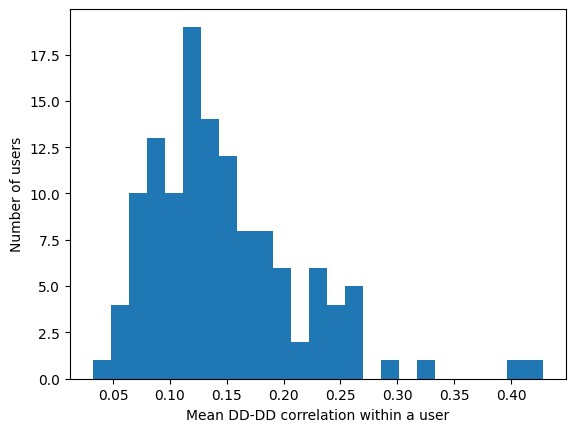

In [28]:
pairs = [df[df.subject == u][DD].corr().values for u in df.subject.unique()]
tempo = [p[~np.eye(len(DD), dtype=bool)].mean() for p in pairs]
plt.hist(tempo, bins=25); plt.xlabel("Mean DD-DD correlation within a user"); plt.ylabel("Number of users"); plt.show()

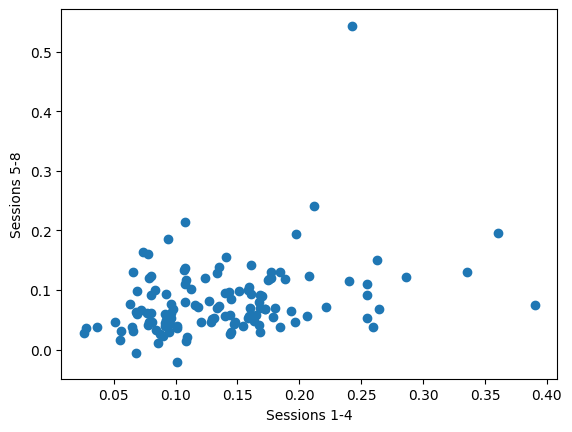

0.3267363354967338


In [29]:
def coupling(d): return d[DD].corr().values[~np.eye(len(DD), dtype=bool)].mean()
a = [coupling(df[(df.subject == u) & (df.sessionIndex <= 4)]) for u in df.subject.unique()]
b = [coupling(df[(df.subject == u) & (df.sessionIndex > 4)]) for u in df.subject.unique()]
plt.scatter(a, b); plt.xlabel("Sessions 1-4"); plt.ylabel("Sessions 5-8"); plt.show()
print(np.corrcoef(a, b)[0, 1])

In [30]:
for u in ["s138", "s147", "s316", "s319"]:
    c = df[df.subject == u][DD].corr().values
    print(u, round(c[~np.eye(len(DD), dtype=bool)].mean(), 3))

s138 0.267
s147 0.192
s316 0.15
s319 0.429


## Box-plot per user(sorted by median)

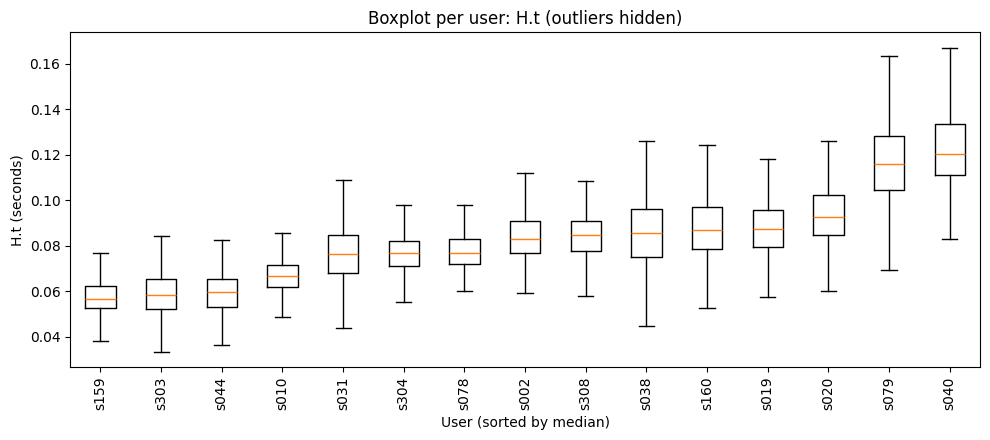

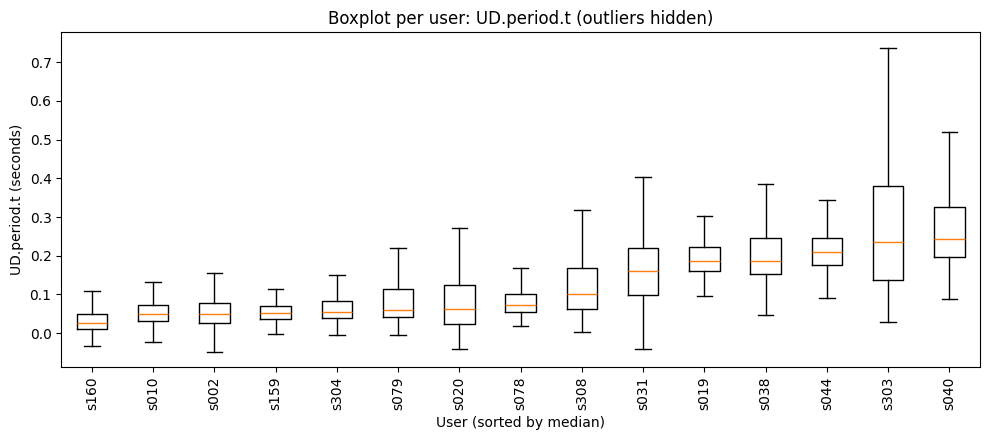

In [31]:
users15 = pick(15)
for feat in (H[1], UD[0]):
    sub = df[df.subject.isin(users15)]
    order = sub.groupby("subject")[feat].median().sort_values().index
    data = [sub.loc[sub.subject == u, feat].values for u in order]
    plt.figure(figsize=(10, 4.5))
    plt.boxplot(data, showfliers=False)   # fliers hidden so long tails don't squash the boxes
    plt.xticks(range(1, len(order) + 1), order, rotation=90)
    plt.xlabel("User (sorted by median)")
    plt.ylabel(f"{feat} (seconds)")
    plt.title(f"Boxplot per user: {feat} (outliers hidden)")
    finish(f"box_{feat}")

### Violin plot

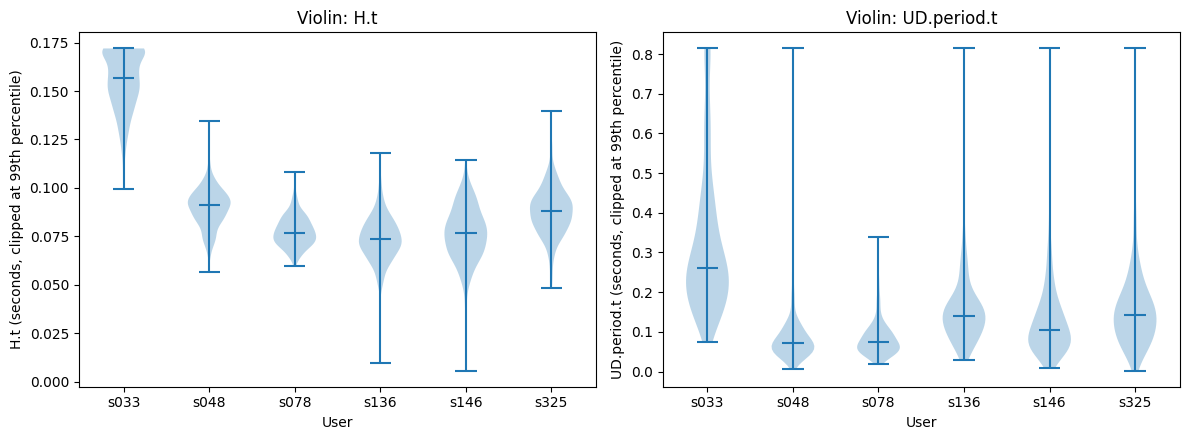

In [32]:
users6 = pick(6)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, feat in zip(axes, (H[1], UD[0])):
    data = [df.loc[df.subject == u, feat].clip(upper=df[feat].quantile(0.99)).values for u in users6]
    ax.violinplot(data, showmedians=True)
    ax.set_xticks(range(1, len(users6) + 1))
    ax.set_xticklabels(users6)
    ax.set_xlabel("User")
    ax.set_ylabel(f"{feat} (seconds, clipped at 99th percentile)")
    ax.set_title(f"Violin: {feat}")
finish("violin")

### Skewness before and after Yeo-Johnson

Skewness (0 = symmetric; above ~1 = strongly right-skewed):
                 skew_before  skew_after
H.period                0.87       -0.00
H.t                     0.89        0.01
H.i                     0.96        0.03
H.e                     1.28       -0.01
H.five                  0.83        0.00
H.Shift.r               0.49        0.01
H.o                     2.40       -0.06
H.a                     4.52       -0.02
H.n                     1.18       -0.01
H.l                     0.60       -0.02
H.Return                0.49       -0.01
DD.period.t            10.36        0.19
DD.t.i                  8.62       -0.02
DD.i.e                 78.62        0.13
DD.e.five               3.60        0.19
DD.five.Shift.r         7.08        0.11
DD.Shift.r.o            4.93        0.16
DD.o.a                  5.93        0.00
DD.a.n                  6.72        0.01
DD.n.l                  4.54        0.06
DD.l.Return             6.20        0.00
UD.period.t            10.03        0.

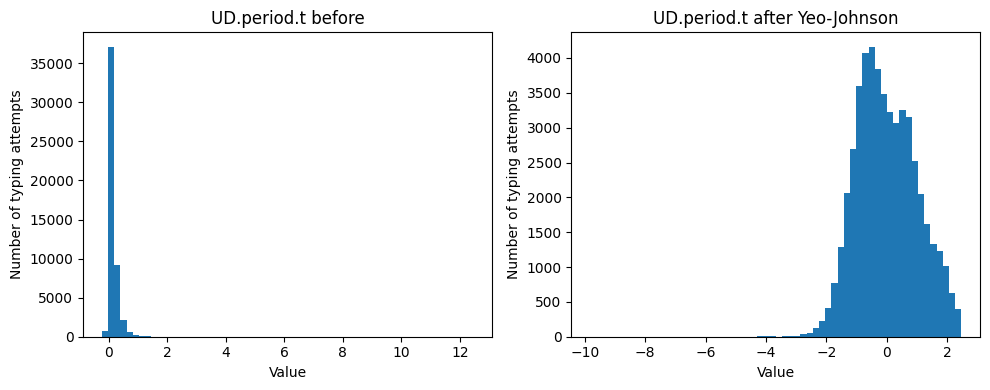

In [33]:
pt = PowerTransformer(method="yeo-johnson")          # handles negative UD values
X_pt = pd.DataFrame(pt.fit_transform(df[feats]), columns=feats)
sk = pd.DataFrame({"skew_before": skew(df[feats]), "skew_after": skew(X_pt)}, index=feats).round(2)
print("Skewness (0 = symmetric; above ~1 = strongly right-skewed):")
print(sk.to_string())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(df[UD[0]], bins=60)
axes[0].set_title(f"{UD[0]} before")
axes[1].hist(X_pt[UD[0]], bins=60)
axes[1].set_title(f"{UD[0]} after Yeo-Johnson")
for ax in axes:
    ax.set_xlabel("Value")
    ax.set_ylabel("Number of typing attempts")
finish("skew_before_after")

### PCA

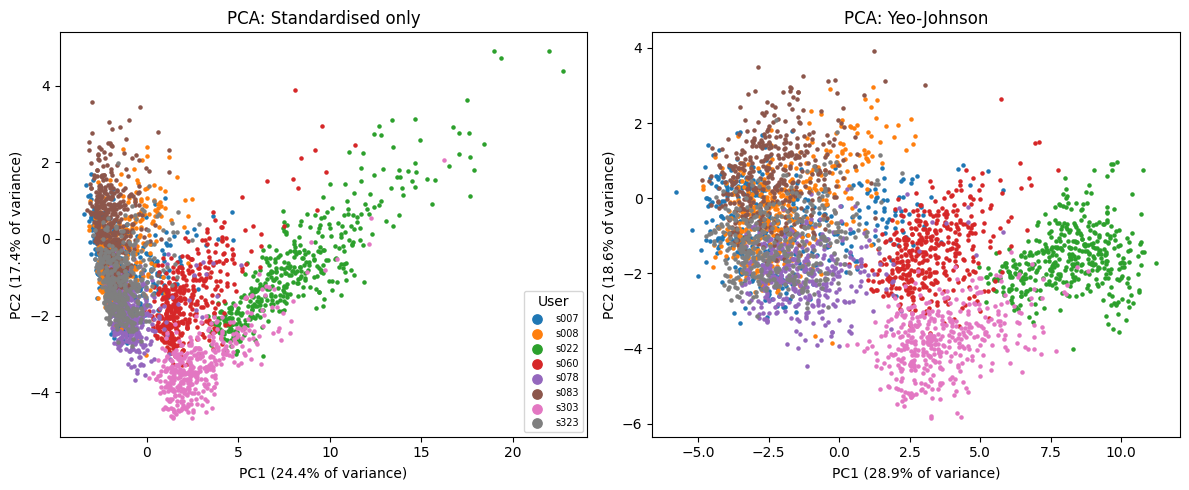

In [34]:
users8 = pick(8)
mask = df.subject.isin(users8).values
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, X) in zip(axes, [("Standardised only", StandardScaler().fit_transform(df[feats])),
                                  ("Yeo-Johnson", X_pt.values)]):
    p = PCA(n_components=2)
    Z = p.fit_transform(X)[mask]
    v = p.explained_variance_ratio_ * 100
    for u in users8:
        m = (df.subject.values[mask] == u)
        ax.scatter(Z[m, 0], Z[m, 1], s=5, label=u)
    ax.set_xlabel(f"PC1 ({v[0]:.1f}% of variance)")
    ax.set_ylabel(f"PC2 ({v[1]:.1f}% of variance)")
    ax.set_title(f"PCA: {title}")
axes[0].legend(markerscale=3, title="User", fontsize=7)
finish("pca_before_after")

### Scree plot

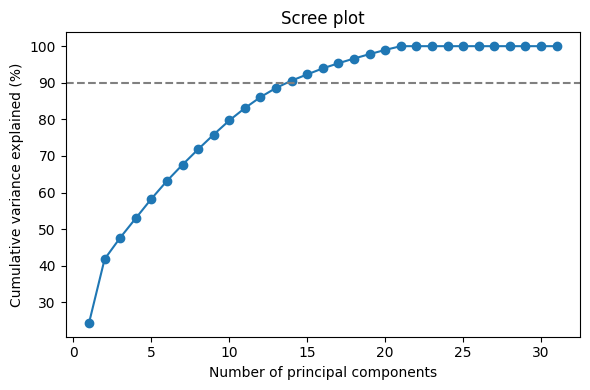

Components needed for 90% variance: 14 of 31


In [36]:
pca_full = PCA().fit(StandardScaler().fit_transform(df[feats]))
cum = np.cumsum(pca_full.explained_variance_ratio_) * 100
plt.figure(figsize=(6, 4))
plt.plot(range(1, len(cum) + 1), cum, marker="o")
plt.axhline(90, ls="--", c="gray")
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative variance explained (%)")
plt.title("Scree plot")
finish("scree")
print("Components needed for 90% variance:", int(np.argmax(cum >= 90)) + 1, "of", len(feats))

### t-Sne

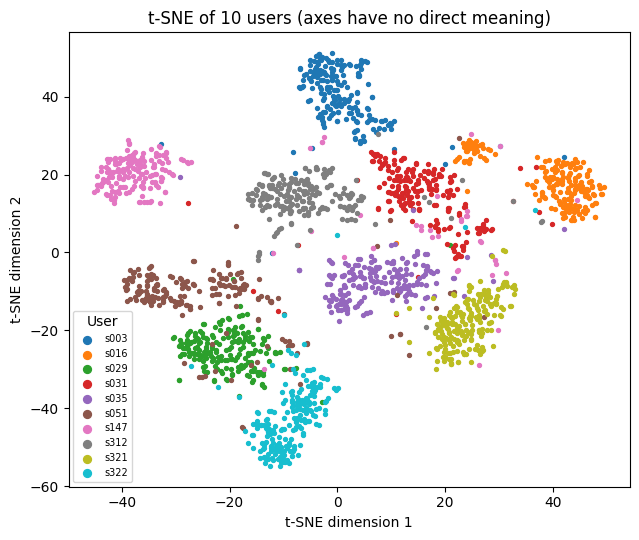

In [37]:
users10 = pick(10)
s = df[df.subject.isin(users10)].groupby("subject").sample(n=200, random_state=SEED)   # 200 attempts per user
Z = TSNE(n_components=2, perplexity=30, random_state=SEED, init="pca").fit_transform(
    PowerTransformer().fit_transform(s[feats]))
plt.figure(figsize=(6.5, 5.5))
for u in users10:
    m = (s.subject.values == u)
    plt.scatter(Z[m, 0], Z[m, 1], s=8, label=u)
plt.legend(markerscale=2, title="User", fontsize=7)
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.title("t-SNE of 10 users (axes have no direct meaning)")
finish("tsne")


### Is D-D coupling a personal trait? (or just varies session by session)

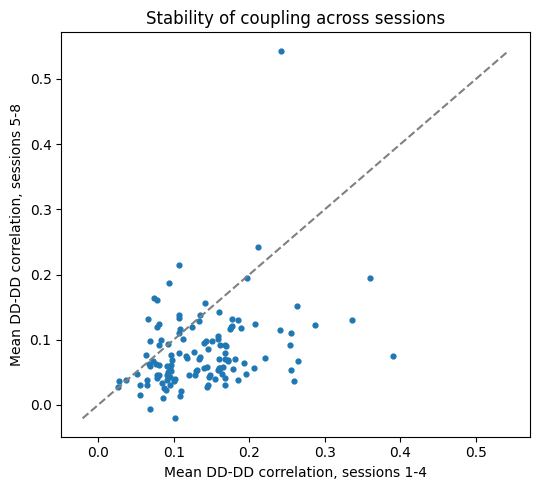

Correlation between the two halves: 0.327


In [38]:
def coupling(d):
    c = d[DD].corr().values
    return c[~np.eye(len(DD), dtype=bool)].mean()

a = [coupling(df[(df.subject == u) & (df.sessionIndex <= 4)]) for u in all_users]
b = [coupling(df[(df.subject == u) & (df.sessionIndex > 4)]) for u in all_users]
plt.figure(figsize=(5.5, 5))
plt.scatter(a, b, s=12)
lim = [min(a + b), max(a + b)]
plt.plot(lim, lim, ls="--", c="gray")
plt.xlabel("Mean DD-DD correlation, sessions 1-4")
plt.ylabel("Mean DD-DD correlation, sessions 5-8")
plt.title("Stability of coupling across sessions")
finish("coupling_stability")
if len(all_users) > 2:
    print("Correlation between the two halves:", round(np.corrcoef(a, b)[0, 1], 3))

### Same coupling with each session's mean removed


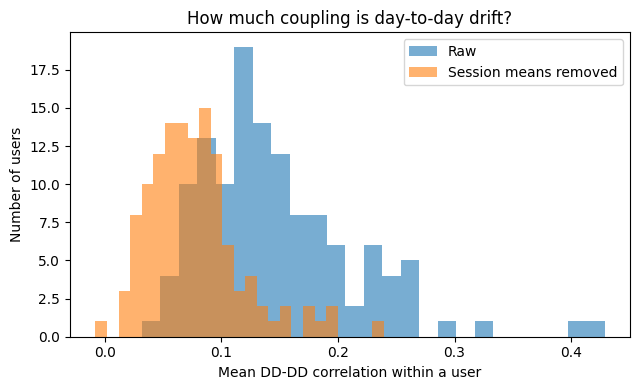

In [39]:
dd = df[DD] - df.groupby(["subject", "sessionIndex"])[DD].transform("mean")
raw = [coupling(df[df.subject == u]) for u in all_users]
cen = [dd[df.subject == u].corr().values[~np.eye(len(DD), dtype=bool)].mean() for u in all_users]
plt.figure(figsize=(6.5, 4))
plt.hist(raw, bins=25, alpha=0.6, label="Raw")
plt.hist(cen, bins=25, alpha=0.6, label="Session means removed")
plt.xlabel("Mean DD-DD correlation within a user")
plt.ylabel("Number of users")
plt.legend()
plt.title("How much coupling is day-to-day drift?")
finish("coupling_session_removed")

In [40]:
# 8. Session drift: train on session 1 only, test on each later session
s1 = df[df.sessionIndex == 1]
clf = make_pipeline(StandardScaler(), KNeighborsClassifier(5)).fit(s1[feats], s1["subject"])
print("\nDrift check (kNN trained on session 1 only):")
for s in sorted(df.sessionIndex.unique())[1:]:
    t = df[df.sessionIndex == s]
    print(f"  session {s}: accuracy {clf.score(t[feats], t['subject']):.3f}")

print("\nSaved plots in results/ (eda_hist, eda_corr, eda_pca).")


Drift check (kNN trained on session 1 only):
  session 2: accuracy 0.522
  session 3: accuracy 0.453
  session 4: accuracy 0.365
  session 5: accuracy 0.358
  session 6: accuracy 0.311
  session 7: accuracy 0.285
  session 8: accuracy 0.255

Saved plots in results/ (eda_hist, eda_corr, eda_pca).


In [41]:
# ---- 2. Session-based split (NOT random) -----------------------------------
# Train on sessions 1-5, test on sessions 6-8. Later sessions are typed on
# different days, so this mimics real use: enroll once, authenticate later.
train = df[df["sessionIndex"] <= 5]
test = df[df["sessionIndex"] > 5]

X_train, y_train = train[feature_cols].values, train["subject"].values
X_test, y_test = test[feature_cols].values, test["subject"].values
print(f"Train: {X_train.shape}, Test: {X_test.shape}")


Train: (31500, 31), Test: (18900, 31)


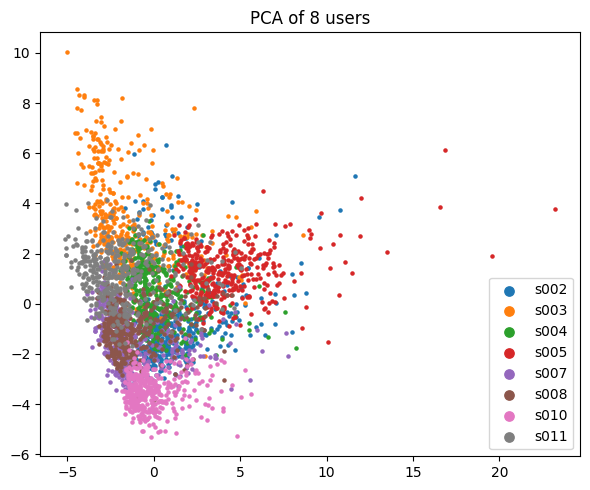

In [43]:
# 7. How separable are users? PCA on a few users
sub = df[df.subject.isin(sorted(df.subject.unique())[:8])]
Z = PCA(n_components=2).fit_transform(StandardScaler().fit_transform(sub[feats]))
plt.figure(figsize=(6, 5))
for u in sub.subject.unique():
    m = (sub.subject == u).values
    plt.scatter(Z[m, 0], Z[m, 1], s=5, label=u)
plt.legend(markerscale=3); plt.title("PCA of 8 users")
plt.tight_layout(); plt.savefig("results/eda_pca.png", dpi=120); plt.show()
